# Zero-shot with CALCE dataset using LSTM module from pytorch 
Objectives: 
- obtain an understanding of how LSTMs operate
- explore the CALCE dataset

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

In [2]:

data = np.load("data/CALCE.npy", allow_pickle=True).item()

print(data.keys())             # dict_keys(['CS2_35', 'CS2_36', 'CS2_37', 'CS2_38'])
df = data["CS2_36"]            # a pandas DataFrame for one cell
print(df.head())

print(df.shape)                # (936, 6)

dict_keys(['CS2_35', 'CS2_36', 'CS2_37', 'CS2_38'])
   cycle  capacity       SoH  resistance         CCCT         CVCT
0    1.0  1.133807  0.825405    0.091628  6671.683200  2212.998635
1    2.0  1.133413  0.825388    0.091628  6666.933312  2204.373626
2    3.0  1.132829  0.825391    0.090817  6662.682287  2201.186076
3    4.0  1.127033  0.816240    0.088546  6656.650722  2225.592597
4    5.0  1.126712  0.807060    0.087494  6693.788570  2052.849153
(936, 6)


In [4]:
sns.set_style("whitegrid", {"grid.color": "#e6e5e1", "axes.edgecolor": "#c3c2b7"})
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.labelsize": 10,
                     "axes.spines.top": False, "axes.spines.right": False})

# One fixed color per cell, so each battery keeps its color in every plot
CELL_COLORS = {"CS2_35": "#2a78d6", "CS2_36": "#eb6834", "CS2_37": "#1baf7a", "CS2_38": "#eda100"}

FEATURES = {
    "capacity":   "Discharge capacity (Ah)",
    "SoH":        "State of health",
    "resistance": "Internal resistance (Ω)",
    "CCCT":       "Constant-current charge time (s)",
    "CVCT":       "Constant-voltage charge time (s)",
}

## Exploring the CALCE dataset
Four LiCoO₂ cells (CS2_35–CS2_38), each cycled until failure. The plots use the raw data, so outlier cycles (e.g. capacity dropping near 0, charge times of 0) show up as spikes.

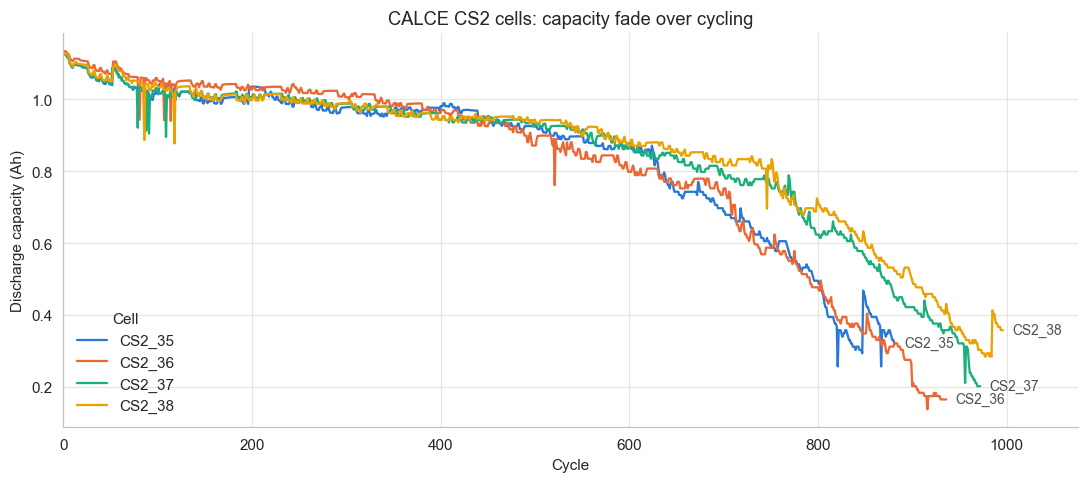

In [5]:
# Capacity fade: the main signal we want the LSTM to forecast
fig, ax = plt.subplots(figsize=(10, 4.5))
for name, cell in data.items():
    ax.plot(cell["cycle"], cell["capacity"], lw=1.5, color=CELL_COLORS[name], label=name)
    # Label each line at its end
    last = cell.iloc[-1]
    ax.annotate(name, (last["cycle"], last["capacity"]), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=9, color="#52514e")
ax.set_title("CALCE CS2 cells: capacity fade over cycling")
ax.set_xlabel("Cycle")
ax.set_ylabel(FEATURES["capacity"])
ax.legend(title="Cell", frameon=False, loc="lower left")
ax.set_xlim(0, max(len(c) for c in data.values()) * 1.08)
plt.tight_layout()
plt.show()


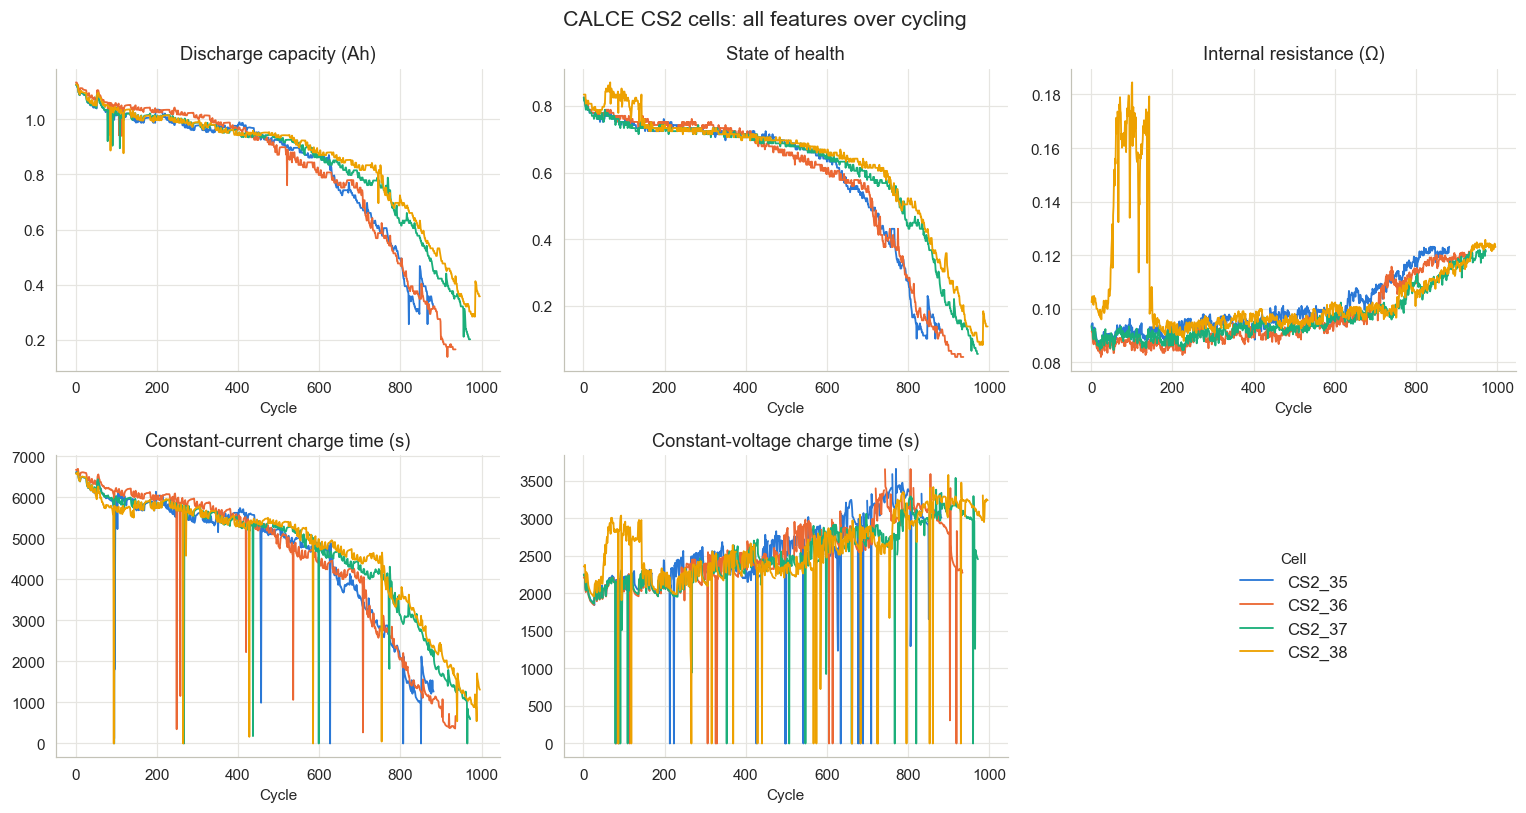

In [6]:
# Every feature vs. cycle, one panel per feature (each panel has its own y-axis)
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5), sharex=True)
for ax, (col, label) in zip(axes.flat, FEATURES.items()):
    for name, cell in data.items():
        ax.plot(cell["cycle"], cell[col], lw=1.2, color=CELL_COLORS[name], label=name)
    ax.set_title(label)
    ax.set_xlabel("Cycle")
    ax.tick_params(labelbottom=True)
axes.flat[-1].axis("off")
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles, labels, title="Cell", frameon=False, loc="center", fontsize=11)
fig.suptitle("CALCE CS2 cells: all features over cycling", fontsize=14)
plt.tight_layout()
plt.show()

CVCT has a few missing values per cell (10–18), which show up as gaps in its panel.

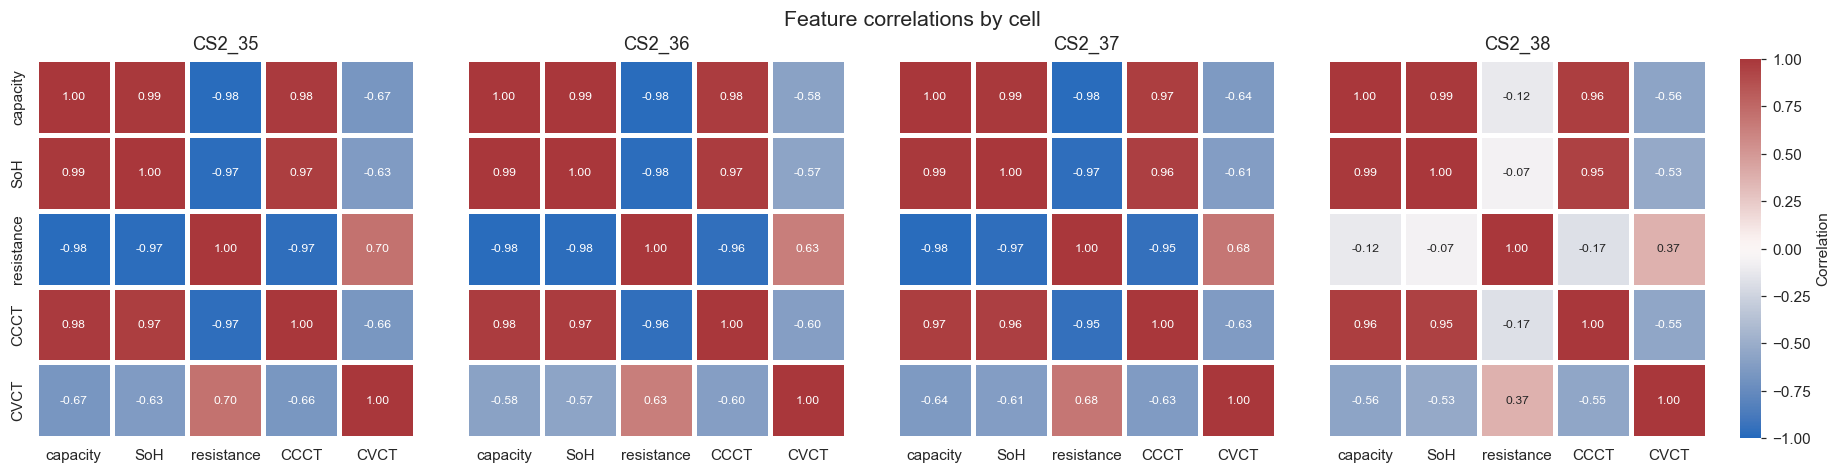

In [7]:
# How the features relate to each other, per cell (Pearson correlation)
fig, axes = plt.subplots(1, len(data) + 1, figsize=(17, 4.2),
                         gridspec_kw={"width_ratios": [1] * len(data) + [0.05]})
cbar_ax = axes[-1]
for i, (ax, (name, cell)) in enumerate(zip(axes[:-1], data.items())):
    corr = cell[list(FEATURES)].corr()
    sns.heatmap(corr, ax=ax, vmin=-1, vmax=1, center=0, cmap="vlag", annot=True, fmt=".2f",
                annot_kws={"fontsize": 8}, square=True, linewidths=2, linecolor="white",
                cbar=(i == 0), cbar_ax=cbar_ax if i == 0 else None,
                cbar_kws={"label": "Correlation"}, yticklabels=(i == 0))
    ax.set_title(name)
fig.suptitle("Feature correlations by cell", fontsize=14)
plt.tight_layout()
plt.show()


# Pearson Correlation Findings: 

## CS2_35
- Capacity -> SoH, CCCT (Constand Current Charging Time), negative with resistance
- SoH -> Capacity, CCCT 
- Resistance -> neg corr w capacity and SoH, pos CVCT but not highly correlated
- CCCT -> capacity, SoH, strong neg w resistance
- CVCT -> maybe resistance, not highly correlated
## CS2_36
- Capacity -> SoH, CCCT (Constand Current Charging Time), negative with resistance
- SoH -> Capacity, CCCT 
- Resistance -> neg corr w capacity and SoH, pos CVCT but not highly correlated
- CCCT -> capacity, SoH, strong neg w resistance
- CVCT -> maybe resistance, not highly correlated 
## CS2_37
- Capacity -> SoH, CCCT (Constand Current Charging Time), negative with resistance
- SoH -> Capacity, CCCT 
- Resistance -> neg corr w capacity and SoH, pos CVCT but not highly correlated
- CCCT -> capacity, SoH, strong neg w resistance
- CVCT -> maybe resistance, not highly correlated 
## CS2_38
- Capacity -> SoH, CCCT (Constand Current Charging Time), no corr w resistance
- SoH -> Capacity, CCCT, no corr w resistance
- Resistance -> CVCT but not highly correlated, no corr w SoH, capacity or CCCT
- CCCT -> capacity, SoH, strong neg w resistance, no corr w resistance
- CVCT -> maybe resistance, not highly correlated 

## Summary 
It's clear across all four sets that Capacity and SoH are strongly correlated with each other. SoH is also correlated with CCCT. 
To estimate SoH, we need to predict on **capacity and CCCT**